# El eje truncado: cómo fabricar un desplome

**Jornada 4 · Bloque 4.4 · Visualización**

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (en inglés, *Runtime → Run all*); la primera vez tarda unos segundos en descargar los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*. Luego mueve los controles. No hace falta tocar el código: está escondido y solo carga los datos y dibuja. Si quieres verlo, pulsa los tres puntos que aparecen en las celdas ocultas.

In [1]:
# Preparación: busca la carpeta del proyecto, carga el estilo del curso y los datos.
# No hace falta tocar nada.
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/, scripts/estilo.py y cuadernos/laboratorio.py."""
    aqui = Path.cwd()
    candidatas = [aqui, *aqui.parents,
                  Path("/content/cursos-analitica-datos"),               # Colab, subida a mano
                  Path("/content/drive/MyDrive/cursos-analitica-datos")]  # Colab, desde Drive
    for carpeta in candidatas:
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "cuadernos" / "laboratorio.py").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab, descarga una vez el material público del curso
        import subprocess
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro el proyecto: abre este cuaderno desde la carpeta cuadernos/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos"):  # ../scripts y la carpeta de este cuaderno
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))

import ipywidgets as widgets
from IPython.display import display

import estilo  # paleta, tipografía y formato numérico español del curso
import laboratorio as lab  # cálculos y gráficos de estos cuadernos

try:  # en Google Colab, los controles necesitan activar este gestor
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

ESTILO = {"description_width": "initial"}
BOTONES = {"description_width": "initial", "button_width": "auto"}

satisfaccion = lab.cargar_satisfaccion(DATOS)
print(f"Datos listos: satisfacción media de {len(satisfaccion)} meses (junio a noviembre de 2025)")

Datos listos: satisfacción media de 6 meses (junio a noviembre de 2025)


## La pregunta

La satisfacción de BiciCiudad baja de 8,05 a 7,93 sobre 10. Con el gráfico adecuado, eso es un desplome
digno de portada. ¿Cuánto drama se puede fabricar sin cambiar ni un dato?

## El experimento

Mueve el punto donde empieza el eje vertical, de 0 a casi el valor más bajo. El indicador de la derecha
dice cuántas veces parece mayor la caída de noviembre de lo que es. El estado inicial es el del cuadro de
mando del curso: el eje empieza en 7,90.

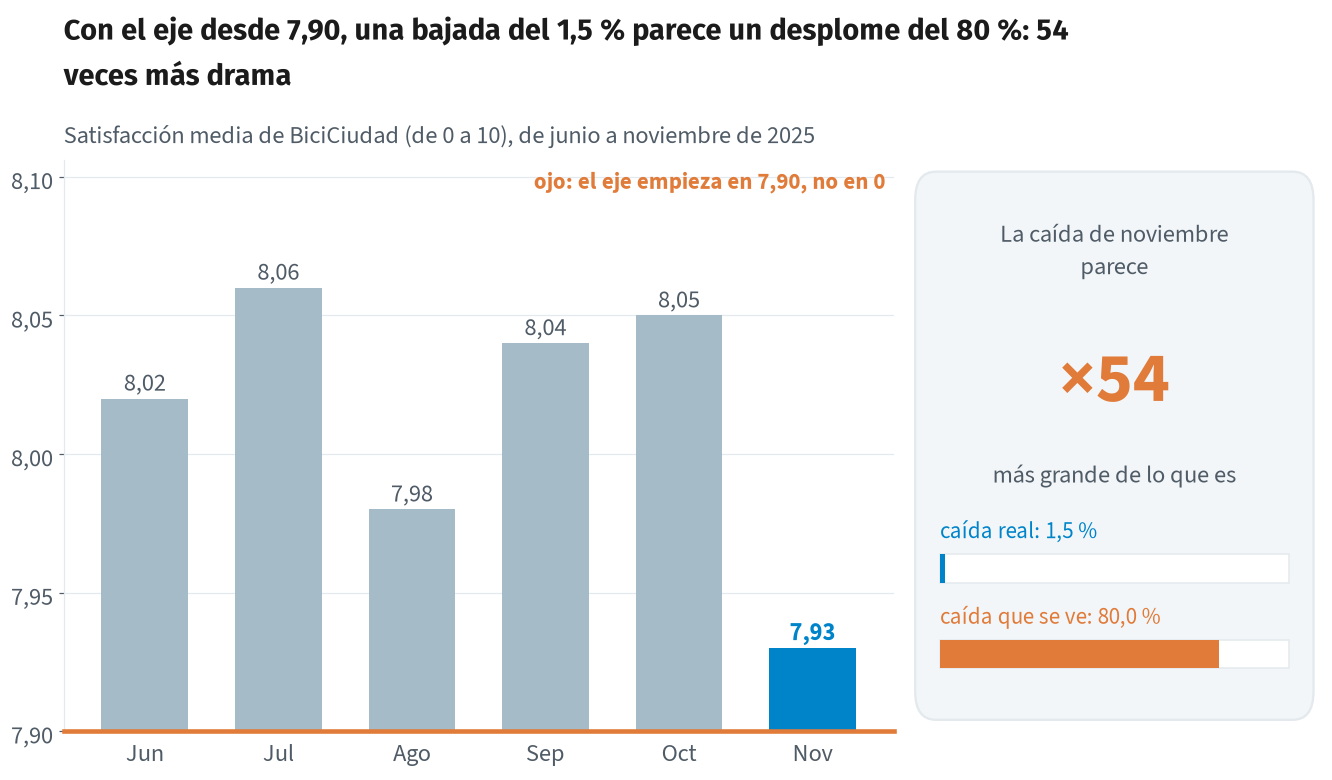

In [2]:
# El experimento: los mismos datos, con el eje empezando en otro sitio.
valores = [0, 1, 2, 3, 4, 5, 6, 7, 7.25, 7.5, 7.6, 7.7, 7.8, 7.85, 7.9, 7.92]
inicio = widgets.SelectionSlider(
    options=[(estilo.num(x, 2 if x % 1 else 0), x) for x in valores], value=7.9, continuous_update=False,
    description="El eje vertical empieza en:", style=ESTILO, layout=widgets.Layout(width="650px"))


def dibujar(inicio):
    lab.mostrar(lab.dibujar_eje(satisfaccion, inicio))


grafico = widgets.interactive_output(dibujar, {"inicio": inicio})
display(widgets.VBox([inicio, grafico]))

## Qué observar

1. Con el eje desde 0, ¿alguien convocaría una reunión?
2. ¿A partir de qué valor del eje la caída empieza a «parecer» grave?
3. La bajada real es de 0,12 puntos. ¿Es más o menos que el margen de error de una encuesta de
   satisfacción?
4. ¿Cuándo está justificado no empezar en cero? (Pista: en un gráfico de barras, casi nunca; en una línea
   que muestra una variación pequeña pero importante, a veces, y avisando.)

## Mensaje clave

> **El título del gráfico es la conclusión.**

Y si el título dice «desplome», que lo diga el dato, no el eje.

## Para curiosos

El indicador de la derecha es el «factor de mentira» de Edward Tufte: el tamaño del efecto en el gráfico
dividido entre el tamaño del efecto en los datos. En el avanzado se trabaja cómo pasar del gráfico a una
nota de decisión.